!!pip install pandas scikit-learn matplotlib seaborn

In [1]:
import pandas as pd

In [2]:
from sklearn.datasets import fetch_openml

insurance = fetch_openml(
    data_id=41214,
    as_frame=True,
    parser="auto"
)

df = insurance.frame

In [3]:
df.shape

(678013, 12)

In [4]:
df.columns

Index(['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge',
       'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  str     
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), str(1)
memory usage: 48.5 MB


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
IDpol,678013.0,NaN,NaN,NaN,2621856.921071,1641782.752655,1.0,1157951.0,2272152.0,4046274.0,6114330.0
ClaimNb,678013.0,NaN,NaN,NaN,0.053247,0.240117,0.0,0.0,0.0,0.0,16.0
Exposure,678013.0,NaN,NaN,NaN,0.52875,0.364442,0.002732,0.18,0.49,0.99,2.01
Area,678013,6,C,191880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VehPower,678013.0,NaN,NaN,NaN,6.454631,2.050906,4.0,5.0,6.0,7.0,15.0
VehAge,678013.0,NaN,NaN,NaN,7.044265,5.666232,0.0,2.0,6.0,11.0,100.0
DrivAge,678013.0,NaN,NaN,NaN,45.499122,14.137444,18.0,34.0,44.0,55.0,100.0
BonusMalus,678013.0,NaN,NaN,NaN,59.761502,15.636658,50.0,50.0,50.0,64.0,230.0
VehBrand,678013,11,B12,166024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VehGas,678013,2,'Regular',345877,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.head(10)

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72
5,13.0,1,0.52,E,6,2,38,50,B12,'Regular',3003,R31
6,15.0,1,0.45,E,6,2,38,50,B12,'Regular',3003,R31
7,17.0,1,0.27,C,7,0,33,68,B12,'Diesel',137,R91
8,18.0,1,0.71,C,7,0,33,68,B12,'Diesel',137,R91
9,21.0,1,0.15,B,7,0,41,50,B12,'Diesel',60,R52


In [8]:
df["Area"].unique()

['D', 'B', 'E', 'C', 'F', 'A']
Categories (6, str): ['A', 'B', 'C', 'D', 'E', 'F']

<Axes: xlabel='Area'>

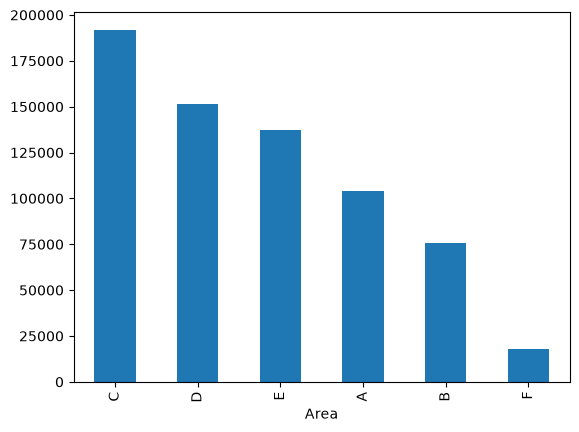

In [9]:
df["Area"].value_counts().plot.bar()

In [10]:
import matplotlib.pyplot as plt

<BarContainer object of 6 artists>

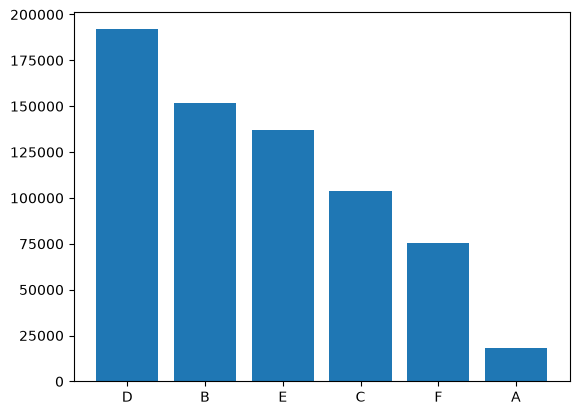

In [11]:
plt.bar(df["Area"].unique().tolist(),df["Area"].value_counts())

<Axes: xlabel='Area'>

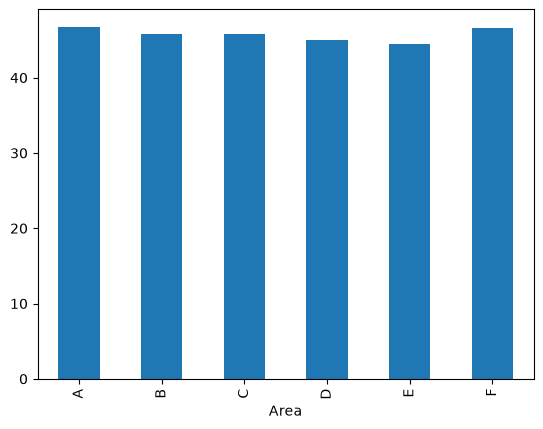

In [12]:
df.groupby("Area")["DrivAge"].mean().plot.bar()

In [13]:
import numpy as np

amacımız tarih kolonu yaratıp tüm satırlara bir tarih kolonu eklemek

In [14]:
randomize = np.random.default_rng(seed = 42)

In [15]:
start_date = pd.Timestamp("2016-01-01")
end_date = pd.Timestamp("2026-12-31")

In [16]:
random_days = randomize.integers(
    low = 0,
    high=(end_date-start_date).days + 1,
    size=len(df)
)

random_days

array([ 358, 3109, 2630, ..., 3806,  348,  979], shape=(678013,))

In [17]:
df["PolicyDate"] = start_date + pd.to_timedelta(random_days, unit="D")
df["PolicyDate"]

0        2016-12-24
1        2024-07-06
2        2023-03-15
3        2020-10-29
4        2020-10-05
            ...    
678008   2019-09-13
678009   2025-03-12
678010   2026-06-03
678011   2016-12-14
678012   2018-09-06
Name: PolicyDate, Length: 678013, dtype: datetime64[us]

In [18]:
df["PolicyDate"].min(), df["PolicyDate"].max()

(Timestamp('2016-01-01 00:00:00'), Timestamp('2026-12-31 00:00:00'))

In [19]:
df_copy = df.sort_values("PolicyDate", ascending=True)

In [20]:
df_copy.reset_index(drop=True,inplace=True)

In [21]:
df_copy

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,PolicyDate
0,53343.0,0,0.002732,E,7,9,34,51,B2,'Diesel',2044,R24,2016-01-01
1,143235.0,1,1.000000,E,5,9,43,50,B1,'Regular',8549,R82,2016-01-01
2,2147262.0,0,0.730000,B,5,9,75,50,B1,'Regular',69,R24,2016-01-01
3,4165280.0,0,1.000000,A,7,4,50,50,B2,'Diesel',32,R24,2016-01-01
4,103538.0,0,0.005464,C,7,16,42,50,B2,'Diesel',194,R93,2016-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
678008,148392.0,0,1.000000,C,8,2,57,50,B2,'Diesel',125,R53,2026-12-31
678009,2285458.0,0,0.500000,E,6,18,60,59,B3,'Regular',4116,R24,2026-12-31
678010,4016865.0,0,0.120000,C,7,3,33,51,B12,'Regular',171,R91,2026-12-31
678011,2258477.0,0,0.490000,E,7,11,52,64,B5,'Regular',3963,R91,2026-12-31


In [22]:
df_copy["VehGas"].unique()

<StringArray>
[''Diesel'', ''Regular'']
Length: 2, dtype: str

In [23]:
df_copy["VehGas"].value_counts()

VehGas
'Regular'    345877
'Diesel'     332136
Name: count, dtype: int64

The car brand divided in the following groups: A- Renaut Nissan and Citroen, B- Volkswagen, Audi, Skoda and Seat, C- Opel, General Motors and Ford, D- Fiat, E- Mercedes Chrysler and BMW, F- Japanese (except Nissan) and Korean, G- other.

In [24]:
df_copy["VehBrand"].unique()

['B2', 'B1', 'B12', 'B3', 'B6', ..., 'B5', 'B11', 'B10', 'B14', 'B4']
Length: 11
Categories (11, str): ['B1', 'B10', 'B11', 'B12', ..., 'B3', 'B4', 'B5', 'B6']

<Axes: xlabel='VehBrand'>

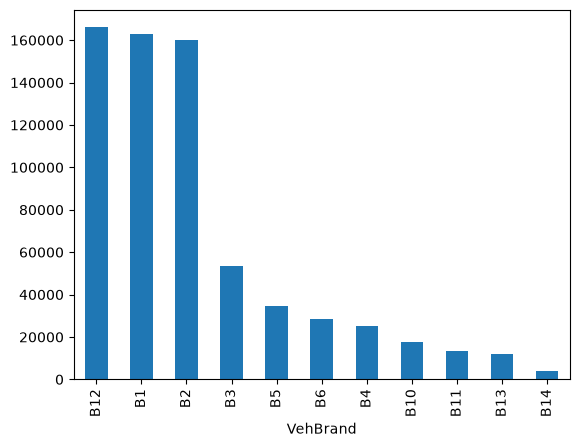

In [25]:
df_copy["VehBrand"].value_counts().plot.bar()

<Axes: xlabel='Region'>

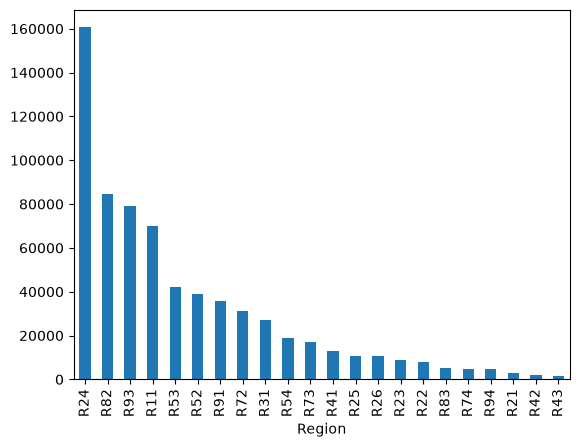

In [26]:
df_copy["Region"].value_counts().plot.bar()

In [27]:
df_copy.groupby("IDpol")["ClaimNb"].count()

IDpol
1.0          1
3.0          1
5.0          1
10.0         1
11.0         1
            ..
6114326.0    1
6114327.0    1
6114328.0    1
6114329.0    1
6114330.0    1
Name: ClaimNb, Length: 678013, dtype: int64

<Axes: xlabel='PolicyDate'>

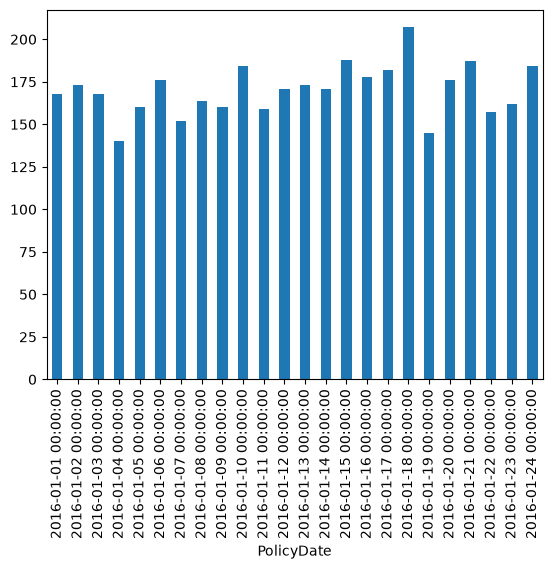

In [ ]:
df_copy.groupby("PolicyDate"d)["IDpol"].count().head(24).plot.bar()

In [32]:
df_copy["PolicyDate"].dt.year

0         2016
1         2016
2         2016
3         2016
4         2016
          ... 
678008    2026
678009    2026
678010    2026
678011    2026
678012    2026
Name: PolicyDate, Length: 678013, dtype: int32

In [33]:
df_copy["PolicyMonth"] = df_copy["PolicyDate"].dt.year.astype("str") + "-" + df_copy["PolicyDate"].dt.month.astype("str")

In [34]:
df_copy

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,PolicyDate,PolicyMonth
0,53343.0,0,0.002732,E,7,9,34,51,B2,'Diesel',2044,R24,2016-01-01,2016-1
1,143235.0,1,1.000000,E,5,9,43,50,B1,'Regular',8549,R82,2016-01-01,2016-1
2,2147262.0,0,0.730000,B,5,9,75,50,B1,'Regular',69,R24,2016-01-01,2016-1
3,4165280.0,0,1.000000,A,7,4,50,50,B2,'Diesel',32,R24,2016-01-01,2016-1
4,103538.0,0,0.005464,C,7,16,42,50,B2,'Diesel',194,R93,2016-01-01,2016-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678008,148392.0,0,1.000000,C,8,2,57,50,B2,'Diesel',125,R53,2026-12-31,2026-12
678009,2285458.0,0,0.500000,E,6,18,60,59,B3,'Regular',4116,R24,2026-12-31,2026-12
678010,4016865.0,0,0.120000,C,7,3,33,51,B12,'Regular',171,R91,2026-12-31,2026-12
678011,2258477.0,0,0.490000,E,7,11,52,64,B5,'Regular',3963,R91,2026-12-31,2026-12


In [41]:
df_policy_month_grouped = df_copy.groupby("PolicyMonth")["IDpol"].count().reset_index().rename(
    columns = {"IDpol": "IDpol_count"}
)
df_policy_month_grouped

,PolicyMonth,IDpol_count
0,2016-1,5288
1,2016-10,5346
2,2016-11,5094
3,2016-12,5318
4,2016-2,4800
...,...,...
127,2026-5,5174
128,2026-6,5056
129,2026-7,5287
130,2026-8,5256


<BarContainer object of 132 artists>

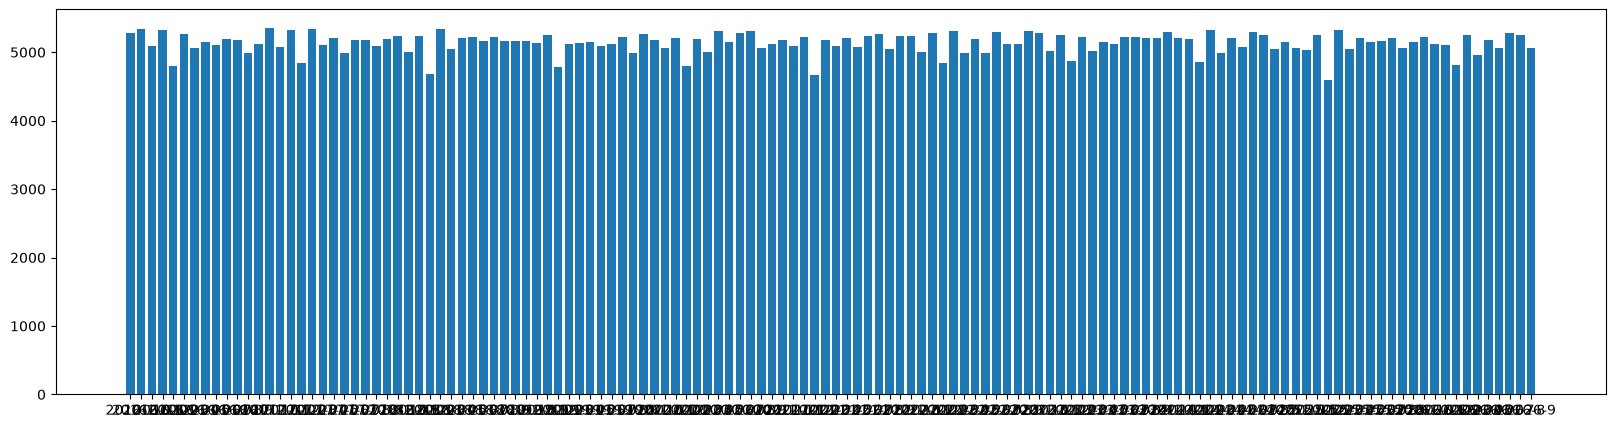

In [45]:
plt.figure(figsize=(20,5))
plt.bar(df_policy_month_grouped["PolicyMonth"], df_policy_month_grouped["IDpol_count"])

In [48]:
df["DrivAge"].apply(lambda x: x**2)

0         3025
1         3025
2         2704
3         2116
4         2116
          ... 
678008    2916
678009    1681
678010    2025
678011    3600
678012     841
Name: DrivAge, Length: 678013, dtype: int64